# EDA Python — Olist Brazilian E-Commerce

## 01. Exploração inicial dos dados

**Objetivo:** estabelecer a conexão com o PostgreSQL e realizar
a inspeção inicial dos dados disponíveis no schema analytics.

**Fonte:** PostgreSQL — banco olist_ecommerce.

In [1]:
# Importação de Bibliotecas
import pandas as pd
from pathlib import Path
print("Diretorio atual: ", Path.cwd())

Diretorio atual:  c:\Users\dyego\Documents\Projetos\Olist Brazilian E-Commerce Dataset\notebooks


In [2]:
import sys
from pathlib import Path

# Identifica a raiz do projeto
BASE_DIR = Path.cwd().parent

# Adiciona a raiz do projeto ao caminho de importação
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

print("Raiz do projeto:", BASE_DIR)

Raiz do projeto: c:\Users\dyego\Documents\Projetos\Olist Brazilian E-Commerce Dataset


In [4]:
from src.database import engine

print("Engine importado com sucesso!")
print("Tipo do objeto:", type(engine))

Engine importado com sucesso!
Tipo do objeto: <class 'sqlalchemy.engine.base.Engine'>


In [6]:
# Consulta teste sql para verificar a conexão com o banco de dados

consulta = "Select * from analytics.orders;"

# Carrega os dados em um DataFrame
df_orders = pd.read_sql(consulta, con=engine)

df_orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [10]:
print(df_orders.shape)
print(df_orders.info())

(99441, 8)
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB
None


In [13]:
df_orders.isna().sum()
df_orders.isna().mean() * 100

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [25]:
# Consolida a quantidade e o percentual de valores ausentes em um único DataFrame

df_nulos = pd.DataFrame({
    'Quantidade de Valores Ausentes': df_orders.isna().sum(),
    'Percentual de Valores Ausentes': df_orders.isna().mean() * 100
})
df_nulos.sort_values('Percentual de Valores Ausentes', ascending=False)

,Quantidade de Valores Ausentes,Percentual de Valores Ausentes
order_delivered_customer_date,2965,2.981668
order_delivered_carrier_date,1783,1.793023
order_approved_at,160,0.160899
order_id,0,0.000000
order_purchase_timestamp,0,0.000000
order_status,0,0.000000
customer_id,0,0.000000
order_estimated_delivery_date,0,0.000000


<Axes: title={'center': 'Distribuição de Status dos Pedidos'}, xlabel='Status do Pedido', ylabel='Percentual (%)'>

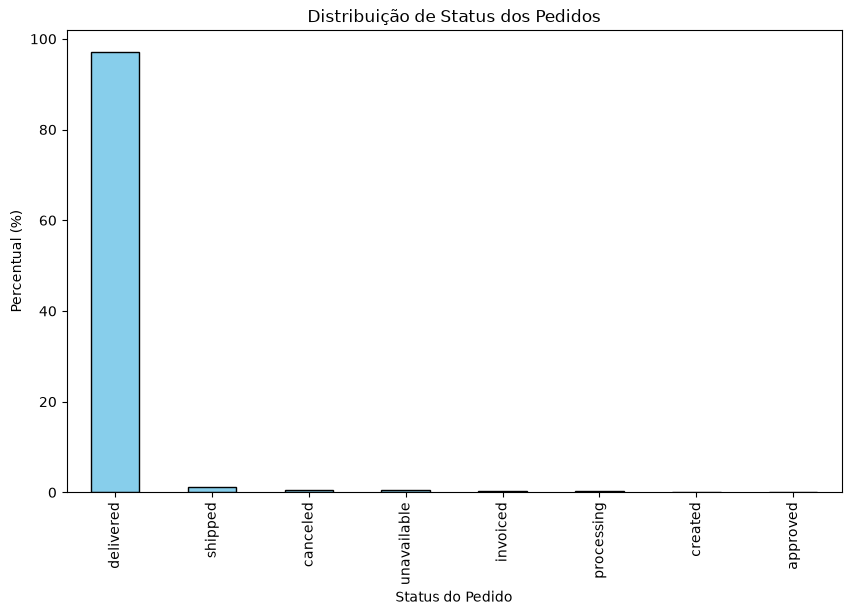

In [ ]:
df_orders_plot =df_orders['order_status'].value_counts(normalize=True) * 100

df_orders_plot.plot.bar(figsize=(10, 6), color='skyblue', edgecolor='black', title='Distribuição de Status dos Pedidos', 
                        xlabel='Status do Pedido', ylabel='Percentual (%)')


In [41]:
# Distribuição de Pedidos por Ano
df_orders['order_purchase_timestamp'].dt.year.value_counts().sort_values(ascending=True)

print("Primeira Compra:", df_orders['order_purchase_timestamp'].min())
print("Última Compra:", df_orders['order_purchase_timestamp'].max())





Primeira Compra: 2016-09-04 21:15:19
Última Compra: 2018-10-17 17:30:18


In [47]:
from sqlalchemy import inspect

# Inspeciona a estrutura do banco de dados
inspector = inspect(engine)

# Lista as tabelas do schema 'analytics'
tabelas = inspector.get_table_names(schema='analytics')

print("Tabelas no banco de dados:")
print(tabelas)
for tabela in tabelas:
    print(tabela)   

Tabelas no banco de dados:
['orders', 'order_payments', 'sellers', 'customers', 'order_reviews', 'geolocation', 'order_items', 'products', 'product_category_name_translation']
orders
order_payments
sellers
customers
order_reviews
geolocation
order_items
products
product_category_name_translation


In [48]:
# Consulta os metadados das colunas de order_items
colunas = inspector.get_columns("order_items", schema="analytics")

for coluna in colunas:
    print(coluna["name"], "-", coluna["type"])

order_id - TEXT
order_item_id - INTEGER
product_id - TEXT
seller_id - TEXT
shipping_limit_date - TIMESTAMP
price - NUMERIC(12, 2)
freight_value - NUMERIC(12, 2)


## Conclusões da exploração inicial

A exploração inicial foi realizada utilizando Python, Pandas e SQLAlchemy, com acesso às tabelas do schema `analytics` no PostgreSQL.

**Principais resultados:**

- A tabela `orders` possui 99.441 registros e 8 colunas, em conformidade com a auditoria SQL.
- Foram identificadas 3 colunas textuais e 5 colunas temporais.
- As maiores proporções de valores ausentes estão relacionadas às datas de entrega.
- Aproximadamente 97,02% dos pedidos possuem status `delivered`.
- O período registrado de compras compreende 04/09/2016 a 17/10/2018.
- Foram identificadas 9 tabelas no schema `analytics`.
- A tabela `order_items` possui 7 colunas e apresenta granularidade por item de pedido.

**Conclusão:** a estrutura inicial dos dados foi validada para prosseguimento da análise exploratória com Python. As verificações realizadas não identificaram divergências nas contagens comparadas com a auditoria SQL.

As próximas análises utilizarão as tabelas necessárias para investigar indicadores comerciais, distribuição geográfica, produtos e desempenho logístico, respeitando a granularidade e os critérios de elegibilidade definidos no projeto.